# Brain tumour detection from MRI
This was a binary CNN project presented at NITK EngiConnect. The network assigns each image one of two dataset labels, tumour or no tumour. The [dataset listing](https://www.kaggle.com/datasets/navoneel/brain-mri-images-for-brain-tumor-detection) dates to 2019. This notebook uses the download from the project archive.

Run the cells in order. The data are fetched into your runtime. The saved plot shows one local TensorFlow 2.7 run using a split by image. The dataset supplies no patient identifiers. This is an educational project with no clinical validation.

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

source = "https://raw.githubusercontent.com/psmithul/portfolio/main/public/code/brain-tumour-detection/src/"
Path("src").mkdir(exist_ok=True)
for name in ("data.py", "train.py", "predict.py"):
    urlretrieve(source + name, str(Path("src") / name))

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
from src.data import fetch_dataset
from src.train import split_images

data_dir = Path("brain_tumor_dataset")
if not data_dir.is_dir():
    fetch_dataset(data_dir)
splits = split_images(data_dir)
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
for ax, label, title in zip(axes, ("no", "yes"), ("No tumour", "Tumour")):
    with Image.open(splits["test"][label][0]) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(title)
    ax.set_axis_off()
plt.show()

In [ ]:
from src.train import train

model_dir = Path("model")
report = train(data_dir, model_dir, epochs=12, batch_size=8)

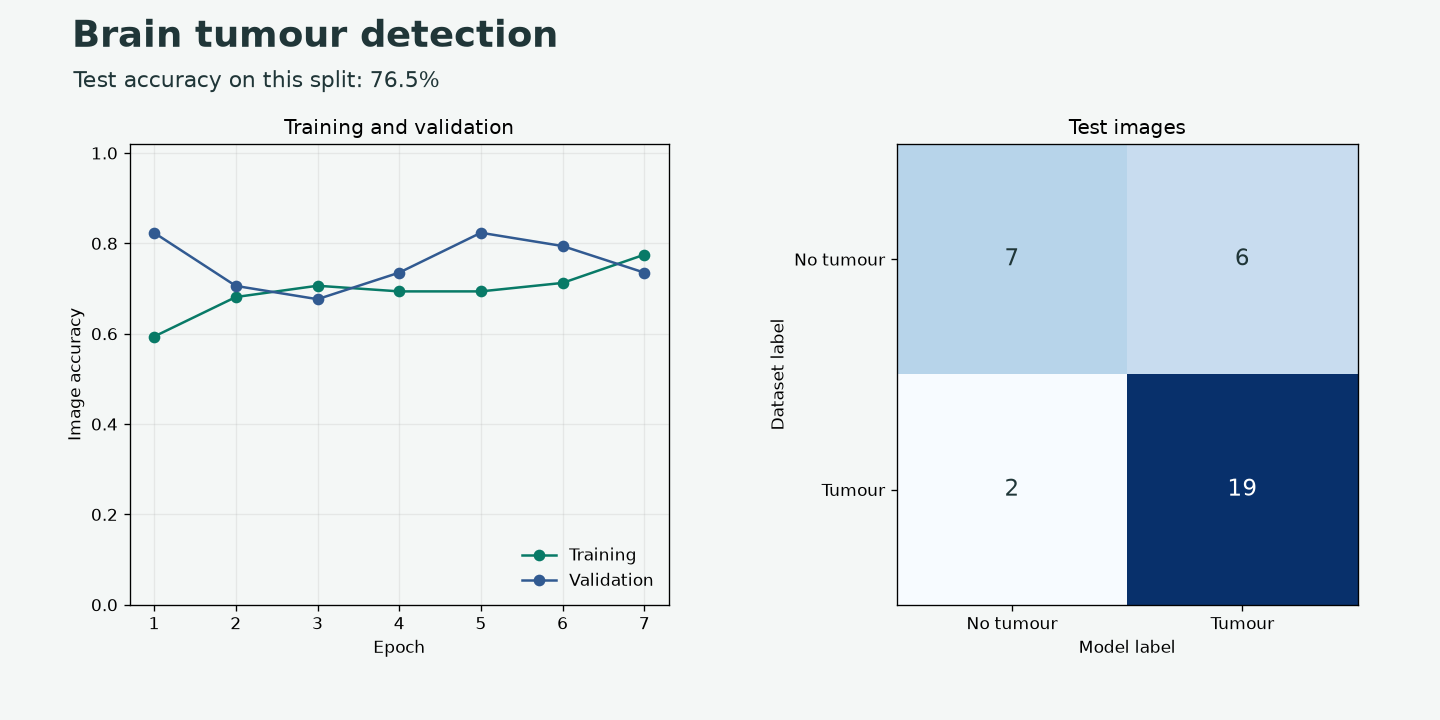

In [4]:
import json

report = json.loads((model_dir / "training.json").read_text())
matrix = report["confusion_matrix"]
history = report["history"]
labels = ["No tumour", "Tumour"]
epochs = range(1, len(history["accuracy"]) + 1)
ink = "#203638"
paper = "#f4f7f6"
fig, (curve, grid) = plt.subplots(1, 2, figsize=(12, 6), facecolor=paper)
fig.subplots_adjust(left=.09, right=.97, bottom=.16, top=.80, wspace=.35)
curve.set_facecolor(paper)
curve.plot(epochs, history["accuracy"], "-o", color="#087a67", label="Training")
curve.plot(epochs, history["val_accuracy"], "-o", color="#315a91", label="Validation")
curve.set(xlabel="Epoch", ylabel="Image accuracy", ylim=(0, 1.02), title="Training and validation")
curve.legend(frameon=False, loc="lower right")
curve.grid(alpha=.22)
grid.imshow(matrix, cmap="Blues")
grid.set_xticks([0, 1], labels)
grid.set_yticks([0, 1], labels)
grid.set(xlabel="Model label", ylabel="Dataset label", title="Test images")
for i, row in enumerate(matrix):
    for j, value in enumerate(row):
        grid.text(j, i, value, ha="center", va="center", fontsize=14,
                  color="white" if value > max(map(max, matrix)) / 2 else ink)
fig.text(.05, .935, "Brain tumour detection", color=ink, fontsize=22, weight="bold")
fig.text(.051, .879, f"Test accuracy on this split: {report['test_accuracy']:.1%}", color=ink, fontsize=13)
plt.show()

In [ ]:
from tensorflow.keras.models import load_model
from src.predict import predict_image

model = load_model(str(model_dir / "bestmodel.h5"), compile=False)
example = splits["test"]["yes"][0]
score = predict_image(model, str(example))
print(f"Model score: {score:.3f}")
print("Model label:", "tumour present" if score >= 0.5 else "no tumour")